In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv('/content/rainfall_data.csv')

print(data.head())

print(data.shape)

         Date      Region  Rainfall_mm  Temperature_C  Humidity_Percent
0  2026-01-01       Salem          0.5           35.5              84.8
1  2026-01-01       Erode         32.9           34.8              71.4
2  2026-01-01  Coimbatore          0.0           32.4              84.3
3  2026-01-02       Salem          0.0           35.9              48.4
4  2026-01-02       Erode          1.1           27.0              67.0
(540, 5)


In [3]:
print(data.info())

print(data.describe())

print(data.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 540 entries, 0 to 539
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Date              540 non-null    object 
 1   Region            540 non-null    object 
 2   Rainfall_mm       540 non-null    float64
 3   Temperature_C     540 non-null    float64
 4   Humidity_Percent  540 non-null    float64
dtypes: float64(3), object(2)
memory usage: 21.2+ KB
None
       Rainfall_mm  Temperature_C  Humidity_Percent
count   540.000000     540.000000        540.000000
mean      7.099259      30.730926         66.762407
std       9.944283       3.444523         11.819912
min       0.000000      23.900000         45.000000
25%       0.200000      27.900000         57.400000
50%       4.050000      30.700000         66.700000
75%       8.300000      33.525000         76.800000
max      57.800000      36.900000         92.500000
Date                0
Region             

In [4]:
data = data.drop_duplicates()

data = data.dropna()

data['Date'] = pd.to_datetime(data['Date'])

print(data.head())

        Date      Region  Rainfall_mm  Temperature_C  Humidity_Percent
0 2026-01-01       Salem          0.5           35.5              84.8
1 2026-01-01       Erode         32.9           34.8              71.4
2 2026-01-01  Coimbatore          0.0           32.4              84.3
3 2026-01-02       Salem          0.0           35.9              48.4
4 2026-01-02       Erode          1.1           27.0              67.0


In [5]:
data['Month'] = data['Date'].dt.month

data['Year'] = data['Date'].dt.year

In [6]:
print(data[['Rainfall_mm',
            'Temperature_C',
            'Humidity_Percent']].corr())

                  Rainfall_mm  Temperature_C  Humidity_Percent
Rainfall_mm          1.000000      -0.065582          0.210762
Temperature_C       -0.065582       1.000000         -0.062446
Humidity_Percent     0.210762      -0.062446          1.000000


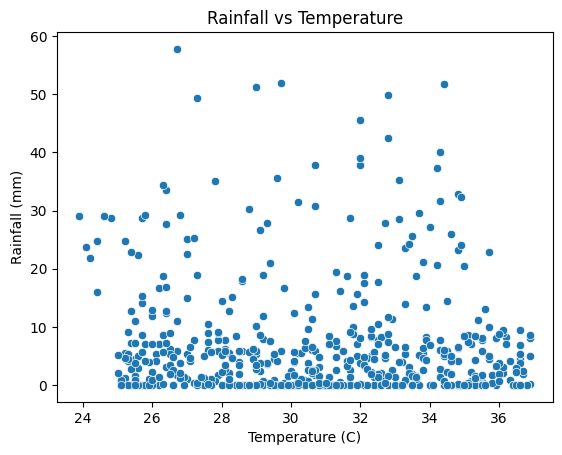

In [7]:
sns.scatterplot(
    data=data,
    x='Temperature_C',
    y='Rainfall_mm'
)

plt.title('Rainfall vs Temperature')
plt.xlabel('Temperature (C)')
plt.ylabel('Rainfall (mm)')

plt.show()

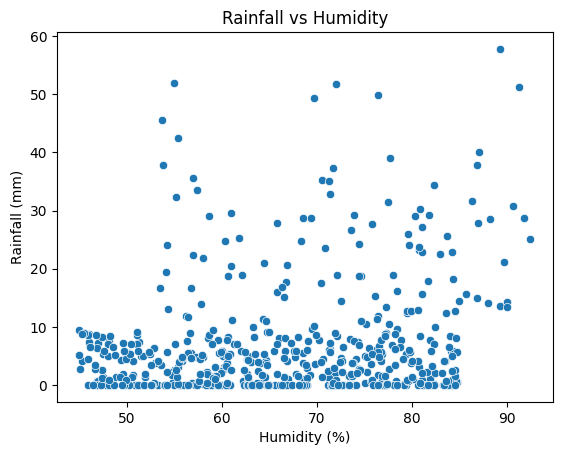

In [8]:
sns.scatterplot(
    data=data,
    x='Humidity_Percent',
    y='Rainfall_mm'
)

plt.title('Rainfall vs Humidity')
plt.xlabel('Humidity (%)')
plt.ylabel('Rainfall (mm)')

plt.show()

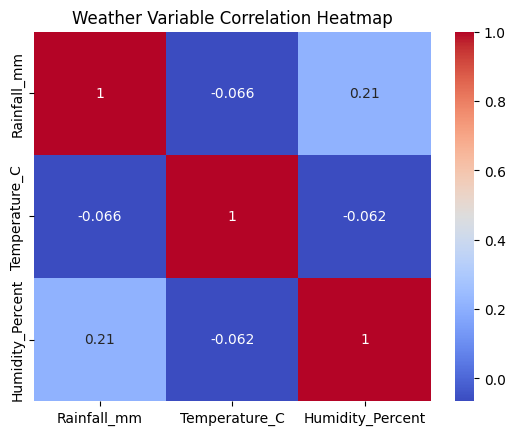

In [9]:
sns.heatmap(
    data[['Rainfall_mm',
          'Temperature_C',
          'Humidity_Percent']].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title('Weather Variable Correlation Heatmap')

plt.show()

In [10]:
daily_rainfall = data.groupby('Date')['Rainfall_mm'].mean()

print(daily_rainfall.head())

Date
2026-01-01    11.133333
2026-01-02     8.400000
2026-01-03     1.933333
2026-01-04     9.666667
2026-01-05     0.566667
Name: Rainfall_mm, dtype: float64


In [11]:
monthly_rainfall = data.groupby('Month')['Rainfall_mm'].mean()

print(monthly_rainfall)

Month
1    4.630108
2    6.482143
3    7.075269
4    5.971111
5    8.813978
6    9.694253
Name: Rainfall_mm, dtype: float64


In [12]:
region_rainfall = data.groupby('Region')['Rainfall_mm'].mean()

print(region_rainfall)

Region
Coimbatore    6.875556
Erode         7.496667
Salem         6.925556
Name: Rainfall_mm, dtype: float64


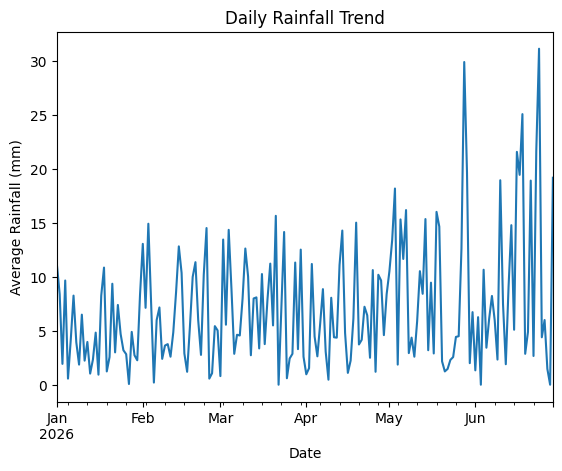

In [13]:
daily_rainfall.plot(kind='line')

plt.title('Daily Rainfall Trend')
plt.xlabel('Date')
plt.ylabel('Average Rainfall (mm)')

plt.show()

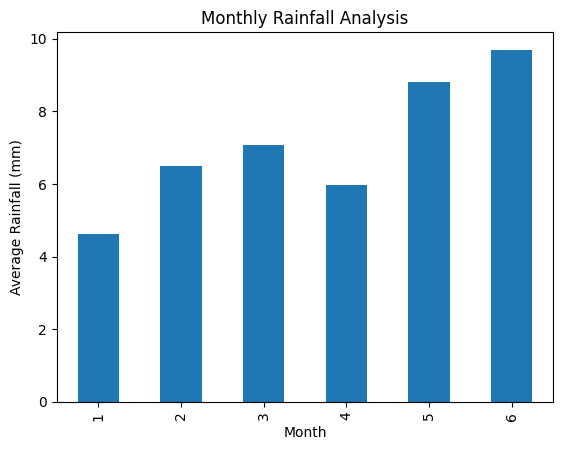

In [14]:
monthly_rainfall.plot(kind='bar')

plt.title('Monthly Rainfall Analysis')
plt.xlabel('Month')
plt.ylabel('Average Rainfall (mm)')

plt.show()

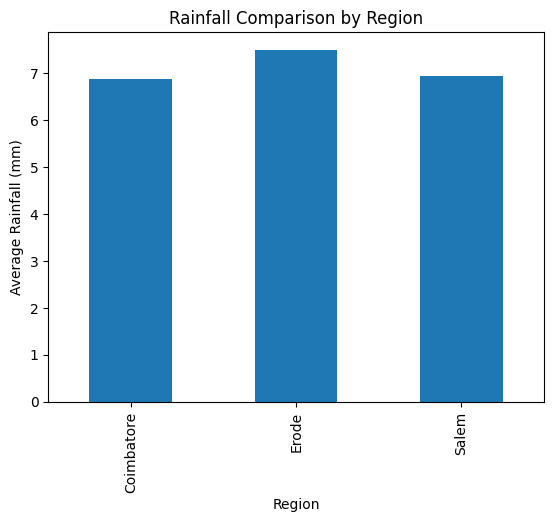

In [15]:
region_rainfall.plot(kind='bar')

plt.title('Rainfall Comparison by Region')
plt.xlabel('Region')
plt.ylabel('Average Rainfall (mm)')

plt.show()